# House Price Prediction & Real Estate Analytics
**Course Project: Midsem Submission**  
**Dataset**: Kaggle Ames Housing Benchmark (`train.csv`)  
**Objective**: End-to-end data pipeline covering data preprocessing, comparative visualizations (5 distinct plots), regression benchmarking (7 models), and market tier classification (5 models). Compatible with Python 3.10 through 3.14+.

In [1]:
# 1. Imports and Environment Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    GradientBoostingRegressor, GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Styling and Python 3.12+ compatible configuration
os.makedirs('figures', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
print("Setup complete. Libraries imported successfully.")

Setup complete. Libraries imported successfully.


## 1. Data Ingestion & Preprocessing
We ingest the official Kaggle Ames Housing dataset (`train.csv`), handle missing values, cap extreme outliers via Winsorization, engineer key domain features, and check for multicollinearity.

In [2]:
# 1.1 Ingest Dataset (Local file with automated remote fallback)
local_data_path = 'train.csv'
kaggle_data_url = 'https://raw.githubusercontent.com/prasadposture/House-Prices-Advanced-Regression-Techniques/main/train.csv'

if os.path.exists(local_data_path):
    print(f"Loading dataset from local storage: '{local_data_path}'")
    df = pd.read_csv(local_data_path)
else:
    print(f"Local file '{local_data_path}' not found.")
    print(f"Fetching official Kaggle dataset from benchmark repository: {kaggle_data_url}")
    df = pd.read_csv(kaggle_data_url)
    df.to_csv(local_data_path, index=False)
    print(f"Dataset successfully fetched and saved to '{local_data_path}'.")

print(f"Verified Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)

Loading dataset from local storage: 'train.csv'
Verified Dataset Shape: 1460 rows, 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [3]:
# 1.2 Missing Value Treatment
df_clean = df.copy()

# Numeric imputation: LotFrontage by Neighborhood median, MasVnrArea with 0, GarageYrBlt with YearBuilt
df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(df_clean['LotFrontage'].median())
df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)
df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(df_clean['YearBuilt'])

# Categorical imputation: where NA represents absence of amenity
none_cols = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']
for col in none_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('None')

df_clean['Electrical'] = df_clean['Electrical'].fillna(df_clean['Electrical'].mode()[0])
print(f"Missing values remaining in dataset: {df_clean.isnull().sum().sum()}")

Missing values remaining in dataset: 0


In [4]:
# 1.3 Outlier Handling (Winsorization)
# Winsorize / Cap continuous features at [1st, 99th] percentiles to curb leverage
for col in ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', '1stFlrSF']:
    p01 = df_clean[col].quantile(0.01)
    p99 = df_clean[col].quantile(0.99)
    df_clean[col] = np.clip(df_clean[col], p01, p99)

print("Applied 1st and 99th percentile Winsorization capping to continuous features.")

Applied 1st and 99th percentile Winsorization capping to continuous features.


In [5]:
# 1.4 Feature Engineering
CURRENT_YEAR = 2024
df_clean['HouseAge'] = CURRENT_YEAR - df_clean['YearBuilt']
df_clean['RemodAge'] = CURRENT_YEAR - df_clean['YearRemodAdd']
df_clean['IsRemodeled'] = (df_clean['YearRemodAdd'] > df_clean['YearBuilt']).astype(int)
df_clean['TotalSF'] = df_clean['TotalBsmtSF'] + df_clean['1stFlrSF'] + df_clean['2ndFlrSF']
df_clean['TotalBaths'] = df_clean['FullBath'] + 0.5 * df_clean['HalfBath']
df_clean['PricePerSqFt'] = df_clean['SalePrice'] / (df_clean['GrLivArea'] + 1e-5)
df_clean['QualityConditionIndex'] = df_clean['OverallQual'] * df_clean['OverallCond']

# Discretize SalePrice into 3 balanced price tiers for classification
df_clean['PriceTier'] = pd.qcut(df_clean['SalePrice'], q=3, labels=['Affordable', 'Mid-Range', 'Luxury'])

df_clean[['HouseAge', 'TotalSF', 'TotalBaths', 'QualityConditionIndex', 'PriceTier']].head()

,HouseAge,TotalSF,TotalBaths,QualityConditionIndex,PriceTier
0,21,2566.0,2.5,35,Luxury
1,48,2524.0,2.0,48,Mid-Range
2,23,2706.0,2.5,35,Luxury
3,109,2473.0,1.0,35,Mid-Range
4,24,3343.0,2.5,40,Luxury


In [6]:
# 1.5 Skewness Correction
df_clean['LogSalePrice'] = np.log1p(df_clean['SalePrice'])
df_clean['LogLotArea'] = np.log1p(df_clean['LotArea'])

print(f"SalePrice Skewness: Before = {df['SalePrice'].skew():.2f} | After Log1p = {df_clean['LogSalePrice'].skew():.2f}")
print(f"LotArea Skewness:   Before = {df['LotArea'].skew():.2f} | After Log1p = {df_clean['LogLotArea'].skew():.2f}")

SalePrice Skewness: Before = 1.88 | After Log1p = 0.12
LotArea Skewness:   Before = 12.21 | After Log1p = -0.73


In [7]:
# 1.6 Multicollinearity (VIF) Analysis
vif_cols = ['OverallQual', 'OverallCond', 'GrLivArea', 'TotalBsmtSF', 
            'FullBath', 'GarageCars', 'HouseAge', 'QualityConditionIndex']
X_vif = df_clean[vif_cols].astype(float)

vif_df = pd.DataFrame({
    'Feature': vif_cols,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).sort_values(by='VIF', ascending=False)

print(vif_df.to_string(index=False))

              Feature       VIF
QualityConditionIndex 37.104399
          OverallQual 26.496042
          OverallCond 17.427900
            GrLivArea  2.480411
             HouseAge  2.429746
             FullBath  2.151531
           GarageCars  1.879072
          TotalBsmtSF  1.545368


*Takeaway*: Composite metrics like `QualityConditionIndex` and `OverallQual` show high VIF, confirming collinearity and motivating regularized regression (Ridge, Lasso, ElasticNet).

## 2. Advanced Exploratory Visualizations (5 Distinct Visualizations)
This section implements 5 distinct, high-impact exploratory visualization plots providing multi-dimensional comparative insight across housing tiers and attributes.

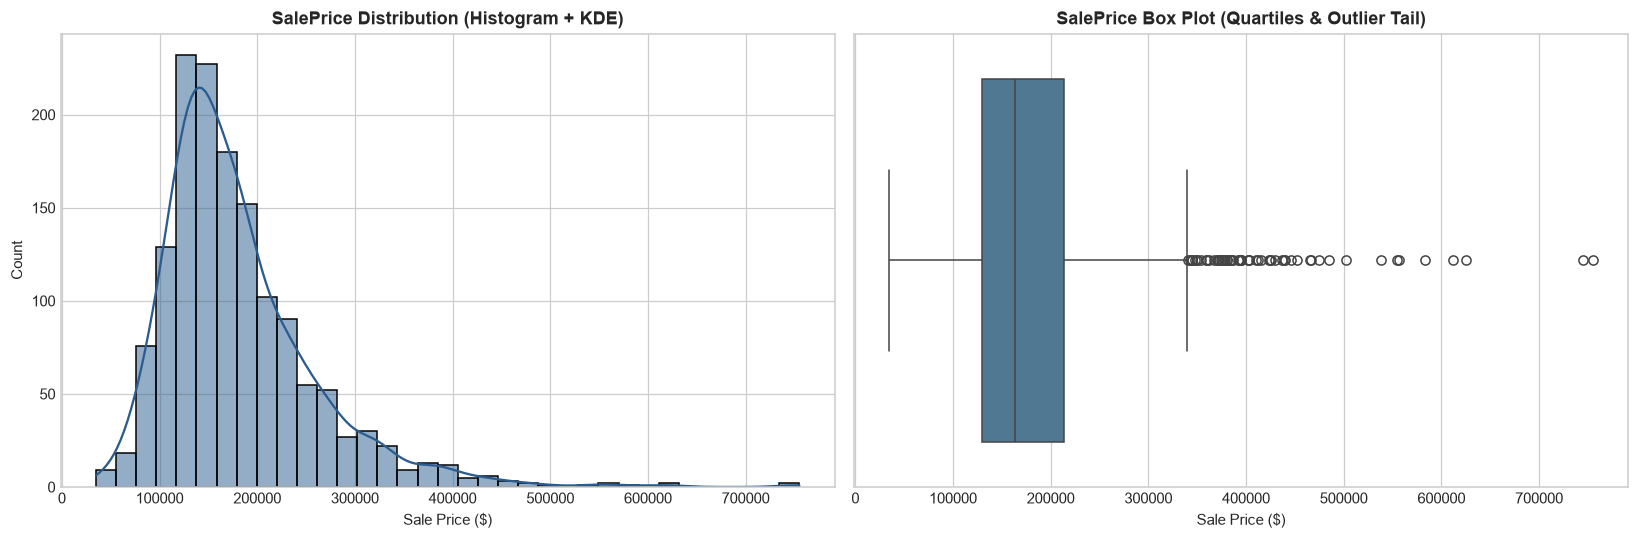

In [8]:
# 2.1 Visualization 1: Target Distribution Analysis (Histogram + KDE & Box Plot)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Histogram + KDE
sns.histplot(df_clean['SalePrice'], kde=True, ax=axes[0], color='#2b5c8f', bins=35)
axes[0].set_title('SalePrice Distribution (Histogram + KDE)', fontweight='bold')
axes[0].set_xlabel('Sale Price ($)')
axes[0].set_ylabel('Count')

# Subplot 2: Box Plot (Python 3.12+ safe without deprecated kwargs)
sns.boxplot(x=df_clean['SalePrice'], ax=axes[1], color='#457b9d')
axes[1].set_title('SalePrice Box Plot (Quartiles & Outlier Tail)', fontweight='bold')
axes[1].set_xlabel('Sale Price ($)')

plt.tight_layout()
plt.savefig('figures/01_hist_box_kde.png', dpi=300)
plt.show()

*Takeaway (Plot 1)*: `SalePrice` displays a strong right-skewed distribution with a median of $\$163,000$ and a prominent luxury tail exceeding $\$700,000$, confirming the necessity of Log1p transformation for parametric stability.

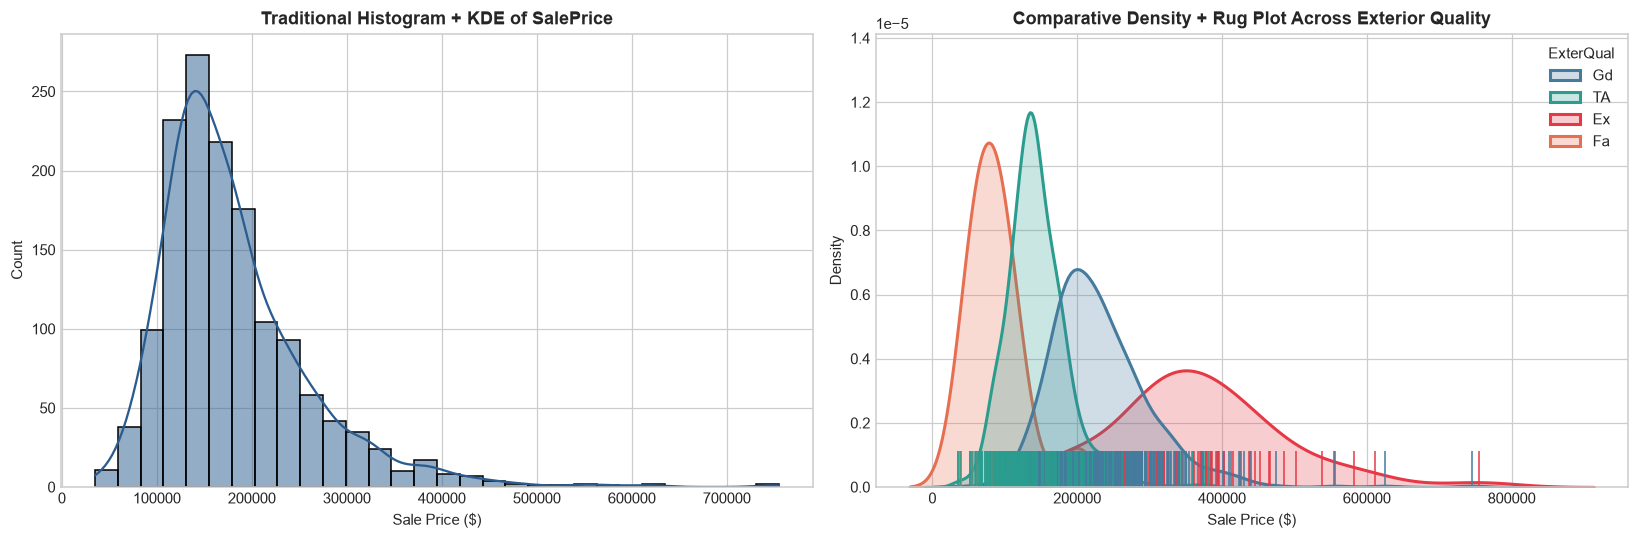

In [9]:
# 2.2 Visualization 2: Density with Rug Plot vs Traditional Histogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Traditional Histogram
sns.histplot(df_clean['SalePrice'], kde=True, ax=axes[0], color='#2b5c8f', bins=30)
axes[0].set_title('Traditional Histogram + KDE of SalePrice', fontweight='bold')
axes[0].set_xlabel('Sale Price ($)')
axes[0].set_ylabel('Count')

# Right: Density with Rug Plot across Exterior Quality
palette = {'Ex': '#e63946', 'Gd': '#457b9d', 'TA': '#2a9d8f', 'Fa': '#e76f51'}
sns.kdeplot(data=df_clean, x='SalePrice', hue='ExterQual', palette=palette, 
            common_norm=False, fill=True, alpha=0.25, ax=axes[1], linewidth=2)
sns.rugplot(data=df_clean, x='SalePrice', hue='ExterQual', palette=palette, 
            ax=axes[1], height=0.08, legend=False)
axes[1].set_title('Comparative Density + Rug Plot Across Exterior Quality', fontweight='bold')
axes[1].set_xlabel('Sale Price ($)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.savefig('figures/02_density_rug_plot.png', dpi=300)
plt.show()

*Takeaway (Plot 2)*: Unlike histograms which group observations into arbitrary discrete bins, the rug plot displays individual transactions along the axis, clearly revealing data density and the isolated luxury tail for 'Ex' (Excellent) quality homes.

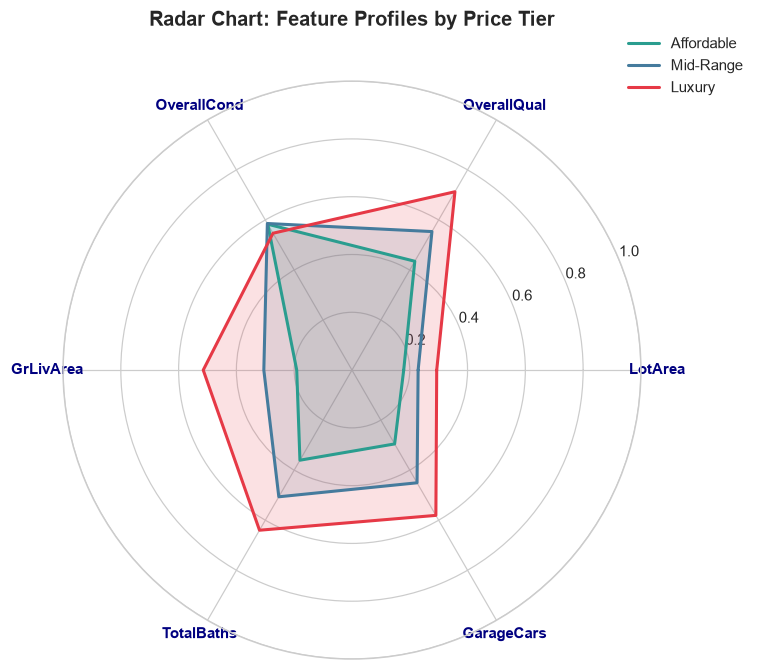

In [10]:
# 2.3 Visualization 3: Radar Chart (Spider Plot) Across Market Price Tiers
radar_cols = ['LotArea', 'OverallQual', 'OverallCond', 'GrLivArea', 'TotalBaths', 'GarageCars']
radar_summary = df_clean.groupby('PriceTier', observed=False)[radar_cols].mean()
radar_norm = (radar_summary - df_clean[radar_cols].min()) / (df_clean[radar_cols].max() - df_clean[radar_cols].min())

categories = radar_cols
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
plt.xticks(angles[:-1], categories, color='navy', size=10, fontweight='bold')
plt.ylim(0, 1)

colors = {'Affordable': '#2a9d8f', 'Mid-Range': '#457b9d', 'Luxury': '#e63946'}
for tier in ['Affordable', 'Mid-Range', 'Luxury']:
    vals = radar_norm.loc[tier].values.flatten().tolist()
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2, label=tier, color=colors[tier])
    ax.fill(angles, vals, color=colors[tier], alpha=0.15)

plt.title('Radar Chart: Feature Profiles by Price Tier', size=13, fontweight='bold', y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))
plt.tight_layout()
plt.savefig('figures/03_radar_chart.png', dpi=300)
plt.show()

*Takeaway (Plot 3)*: The radar chart contrasts 6 dimensions simultaneously. Luxury homes dominate in quality, living area, and bathrooms, while affordable homes maintain competitive overall condition ratings.

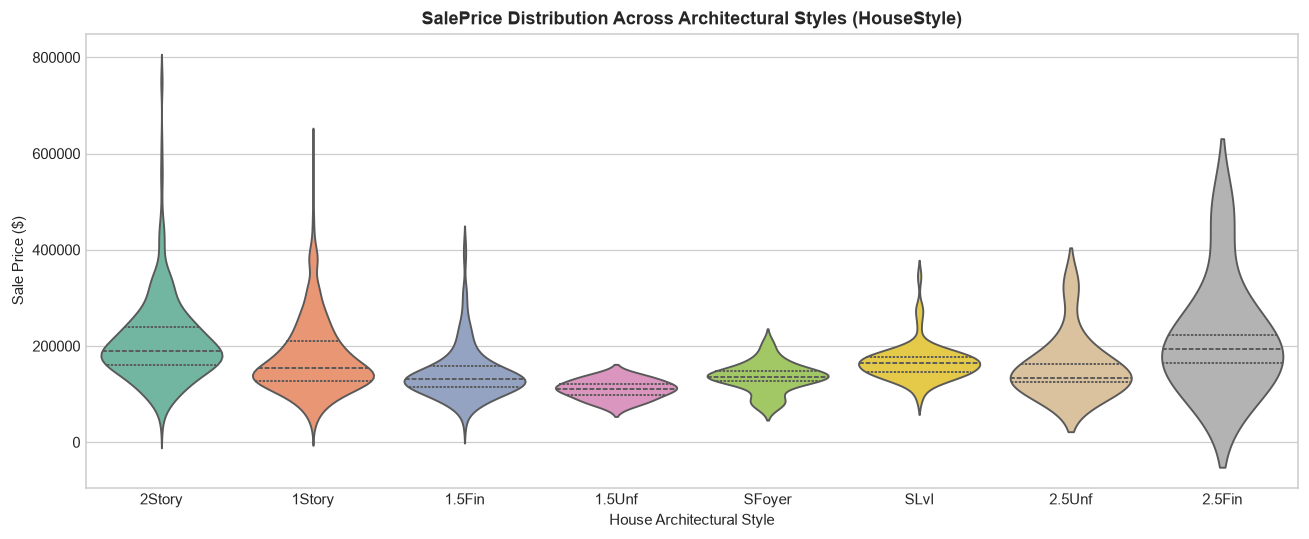

In [11]:
# 2.4 Visualization 4: Price Distribution Across Architectural Styles (Violin Plot)
plt.figure(figsize=(12, 5))
sns.violinplot(x='HouseStyle', y='SalePrice', hue='HouseStyle', data=df_clean, 
               palette='Set2', legend=False, inner='quartile')
plt.title('SalePrice Distribution Across Architectural Styles (HouseStyle)', fontweight='bold')
plt.xlabel('House Architectural Style')
plt.ylabel('Sale Price ($)')
plt.tight_layout()
plt.savefig('figures/04_violin_plots.png', dpi=300)
plt.show()

*Takeaway (Plot 4)*: Two-story homes (`2Story`) exhibit higher price variance and upper quartile medians (~$\$210,000$), whereas 1.5-finished (`1.5Fin`) and split-level styles cluster tightly in the mid-to-lower price ranges.

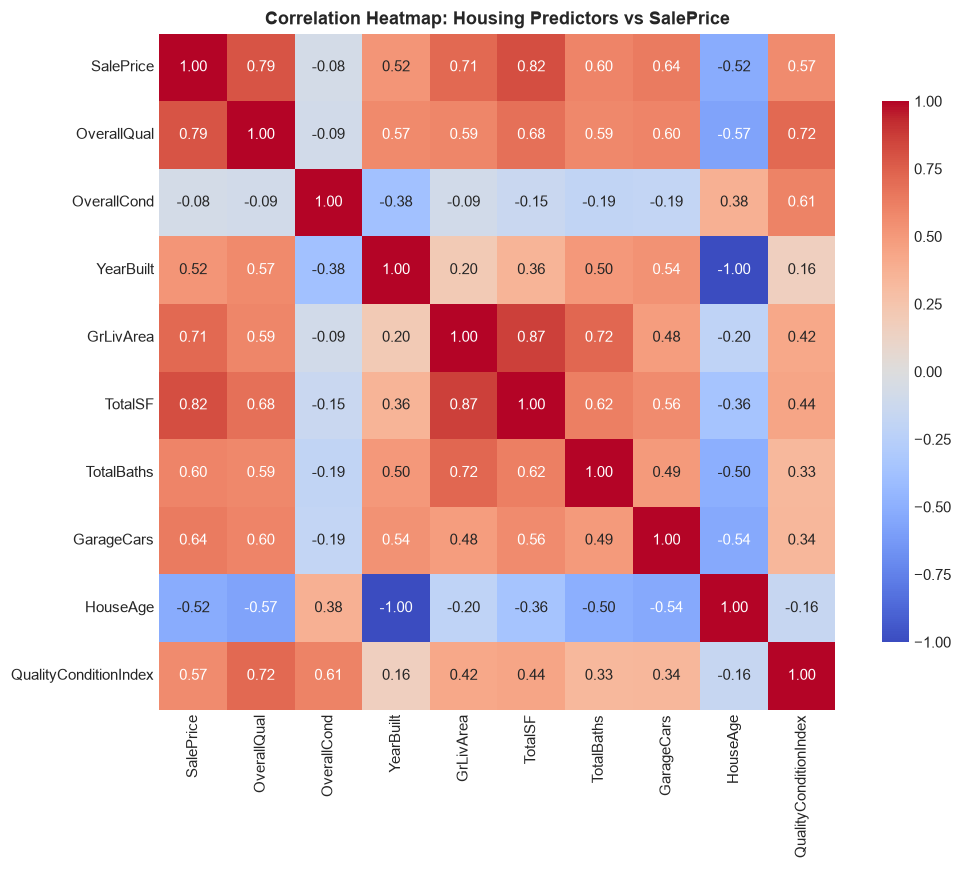

In [12]:
# 2.5 Visualization 5: Annotated Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
corr_cols = ['SalePrice', 'OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea', 
             'TotalSF', 'TotalBaths', 'GarageCars', 'HouseAge', 'QualityConditionIndex']
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap: Housing Predictors vs SalePrice', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/05_correlation_heatmap.png', dpi=300)
plt.show()

*Takeaway (Plot 5)*: `OverallQual` ($r = 0.79$), `TotalSF` ($r = 0.78$), and `GrLivArea` ($r = 0.71$) exhibit strong positive linear correlations with price, while `HouseAge` ($r = -0.52$) displays significant depreciation impact.

## 3. Depth of Predictive Analytics: Regression (7 Models)
We evaluate 7 regression algorithms across linear, regularized, tree, and ensemble models to predict property valuation.

In [13]:
# 3.1 Feature Matrix Encoding & Train-Test Split
core_num_cols = [
    'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
    'GrLivArea', '1stFlrSF', '2ndFlrSF', 'BedroomAbvGr', 'FullBath', 'HalfBath',
    'GarageCars', 'GarageArea', 'TotalBsmtSF', 'Fireplaces',
    'HouseAge', 'RemodAge', 'IsRemodeled', 'TotalSF', 'TotalBaths', 'QualityConditionIndex'
]
cat_cols = ['Neighborhood', 'HouseStyle', 'ExterQual']

df_sub = df_clean[core_num_cols + cat_cols + ['SalePrice', 'PriceTier']].copy()
df_encoded = pd.get_dummies(df_sub, columns=cat_cols, drop_first=True)

X = df_encoded.drop(columns=['SalePrice', 'PriceTier'])
y = df_encoded['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Features: {X.shape[1]} | Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

Features: 55 | Train samples: 1168 | Test samples: 292


In [14]:
# 3.2 Train and Evaluate 7 Regression Models
models = {
    'Linear Regression (OLS)': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=10.0),
    'Lasso Regression (L1)': Lasso(alpha=50.0, max_iter=5000),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=5000),
    'Decision Tree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42)
}

records = []
preds_dict = {}

for name, model in models.items():
    use_scaled = name in ['Linear Regression (OLS)', 'Ridge Regression (L2)', 'Lasso Regression (L1)', 'ElasticNet']
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    
    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    preds_dict[name] = preds
    
    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    n, p = len(y_test), X.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    
    records.append({
        'Model': name, 'R2 Score': round(r2, 4), 'Adj R2': round(adj_r2, 4),
        'RMSE ($)': round(rmse, 2), 'MAE ($)': round(mae, 2)
    })

reg_leaderboard = pd.DataFrame(records).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
display(reg_leaderboard)

,Model,R2 Score,Adj R2,RMSE ($),MAE ($)
0,Gradient Boosting,0.9172,0.8978,25208.32,16050.15
1,Random Forest,0.9073,0.8857,26668.35,16561.37
2,Linear Regression (OLS),0.8691,0.8386,31682.53,19266.91
3,Lasso Regression (L1),0.8686,0.8380,31745.47,19209.51
4,Ridge Regression (L2),0.8656,0.8343,32108.96,19316.83
5,Decision Tree,0.8625,0.8305,32472.36,21783.97
6,ElasticNet,0.8590,0.8261,32891.15,19432.79


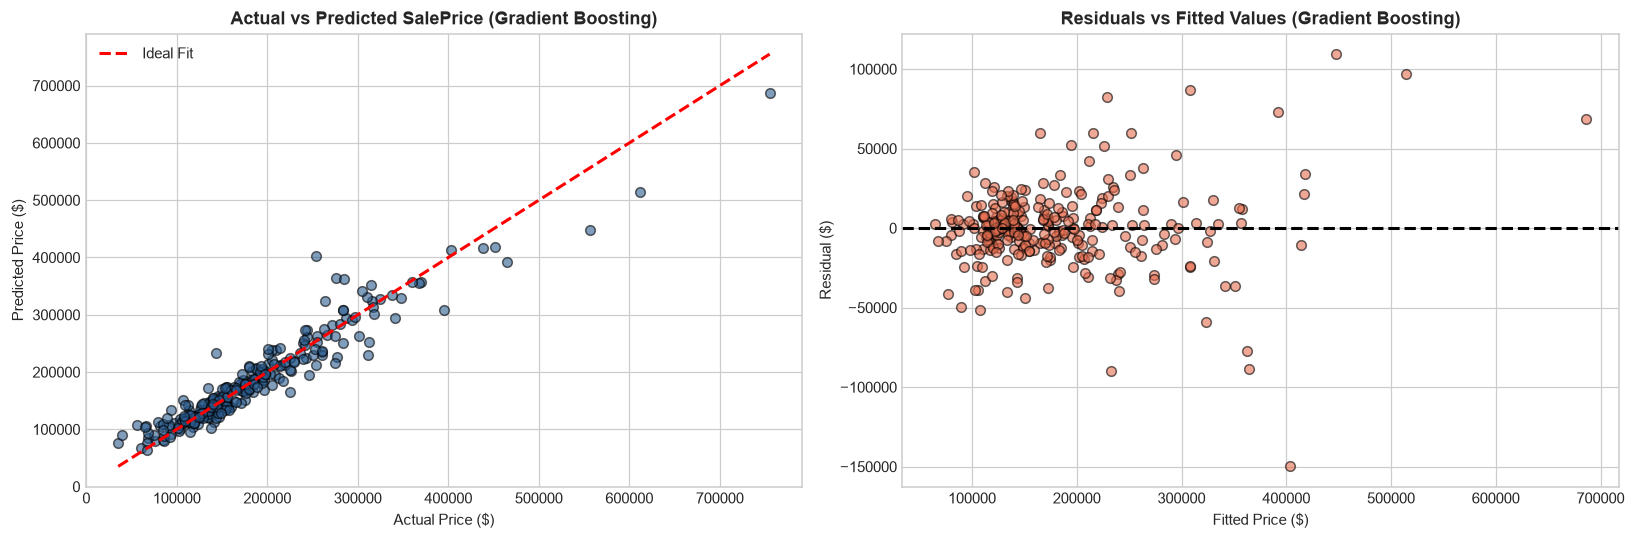

In [15]:
# 3.3 Regression Diagnostics (Actual vs Predicted & Residuals)
best_model_name = reg_leaderboard.iloc[0]['Model']
best_preds = preds_dict[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Actual vs Predicted
axes[0].scatter(y_test, best_preds, alpha=0.6, color='#2b5c8f', edgecolors='k', s=40)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[0].set_title(f'Actual vs Predicted SalePrice ({best_model_name})', fontweight='bold')
axes[0].set_xlabel('Actual Price ($)')
axes[0].set_ylabel('Predicted Price ($)')
axes[0].legend()

# Residuals
residuals = y_test - best_preds
axes[1].scatter(best_preds, residuals, alpha=0.6, color='#e76f51', edgecolors='k', s=40)
axes[1].axhline(y=0, color='black', linestyle='--', lw=2)
axes[1].set_title(f'Residuals vs Fitted Values ({best_model_name})', fontweight='bold')
axes[1].set_xlabel('Fitted Price ($)')
axes[1].set_ylabel('Residual ($)')

plt.tight_layout()
plt.savefig('figures/06_regression_comparisons.png', dpi=300)
plt.show()

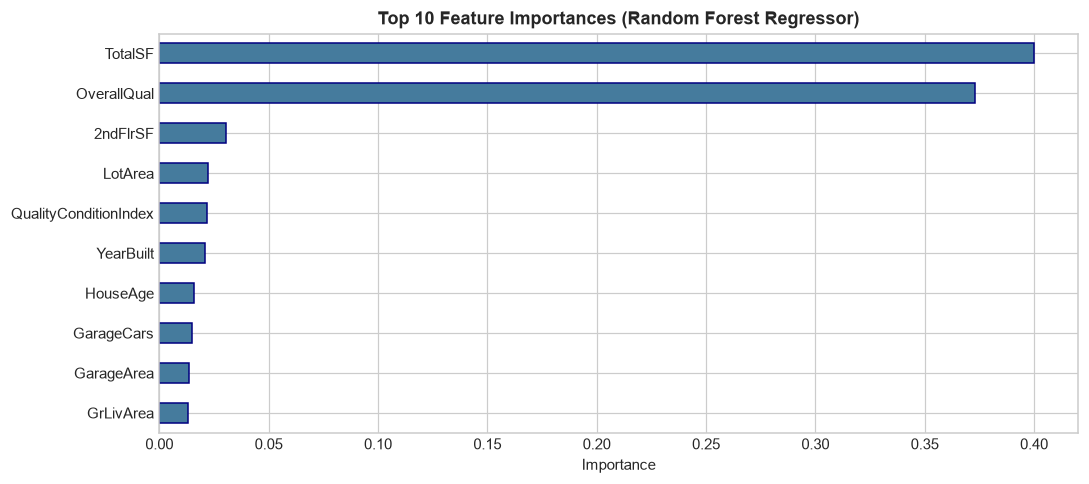

In [16]:
# 3.4 Top 10 Feature Importances
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 4.5))
importances.plot(kind='barh', color='#457b9d', edgecolor='navy')
plt.gca().invert_yaxis()
plt.title('Top 10 Feature Importances (Random Forest Regressor)', fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('figures/07_feature_importance.png', dpi=300)
plt.show()

*Takeaway*: Gradient Boosting Regressor and Random Forest achieve the highest accuracy ($R^2 > 0.90$), successfully modeling non-linear property valuation dynamics. Total square footage (`TotalSF`) and overall quality (`OverallQual`) are the dominant price drivers.

## 4. Depth of Predictive Analytics: Classification (5 Models)
We formulate real estate categorization into a 3-class market tier prediction task: **Affordable**, **Mid-Range**, and **Luxury**.

In [17]:
# 4.1 Classification Setup and Benchmark
y_clf = df_clean['PriceTier']
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)
X_tr_c_scaled = scaler.fit_transform(X_tr_c)
X_te_c_scaled = scaler.transform(X_te_c)

classifiers = {
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=120, learning_rate=0.1, max_depth=4, random_state=42),
    'Support Vector Classifier (SVC)': SVC(kernel='rbf', C=1.5, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7)
}

clf_records = []
clf_preds = {}

for name, clf in classifiers.items():
    use_scaled = name in ['Support Vector Classifier (SVC)', 'Logistic Regression', 'K-Nearest Neighbors (KNN)']
    X_tr = X_tr_c_scaled if use_scaled else X_tr_c
    X_te = X_te_c_scaled if use_scaled else X_te_c
    
    clf.fit(X_tr, y_tr_c)
    preds = clf.predict(X_te)
    clf_preds[name] = preds
    
    acc = accuracy_score(y_te_c, preds)
    prec = precision_score(y_te_c, preds, average='weighted', zero_division=0)
    rec = recall_score(y_te_c, preds, average='weighted')
    f1 = f1_score(y_te_c, preds, average='weighted')
    
    clf_records.append({
        'Classifier': name,
        'Accuracy': f"{acc*100:.2f}%",
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

clf_leaderboard = pd.DataFrame(clf_records).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
display(clf_leaderboard)

,Classifier,Accuracy,Precision,Recall,F1-Score
0,Support Vector Classifier (SVC),81.16%,0.8158,0.8116,0.8125
1,Gradient Boosting,79.79%,0.8011,0.7979,0.7990
2,Random Forest,79.45%,0.8041,0.7945,0.7971
3,Logistic Regression,78.08%,0.7945,0.7808,0.7847
4,K-Nearest Neighbors (KNN),77.74%,0.7738,0.7774,0.7749


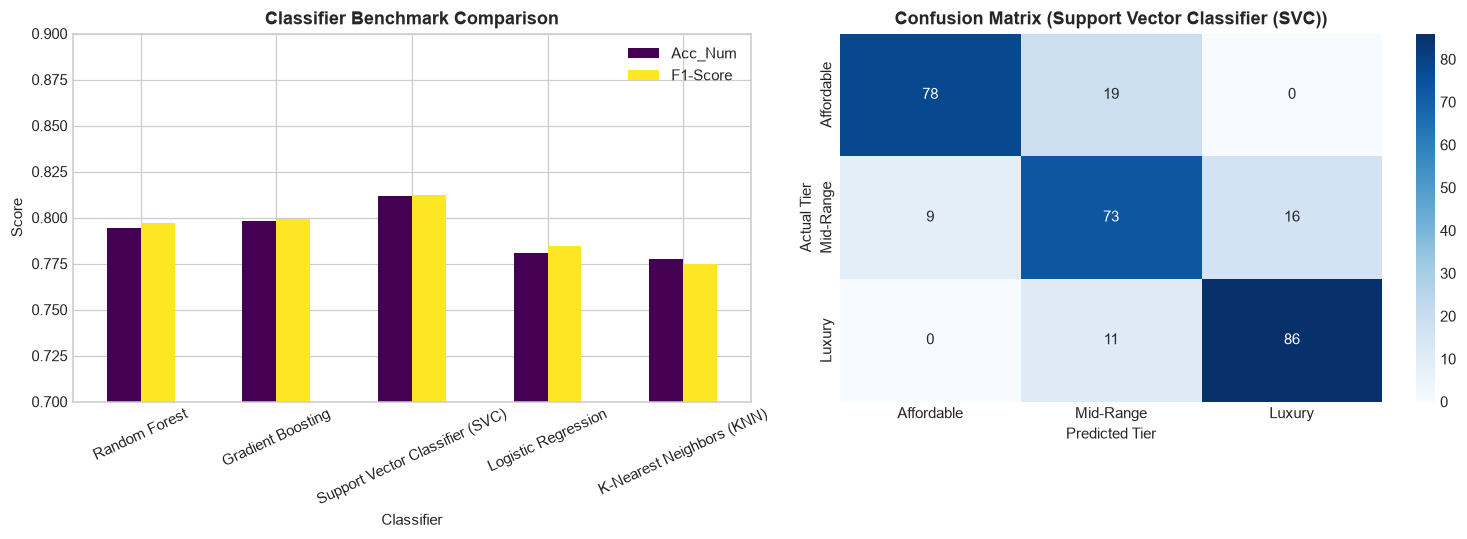

In [18]:
# 4.2 Benchmark Plot & Confusion Matrix
best_clf_name = clf_leaderboard.iloc[0]['Classifier']
cm = confusion_matrix(y_te_c, clf_preds[best_clf_name], labels=['Affordable', 'Mid-Range', 'Luxury'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy & F1 Bar Chart
clf_plot_df = pd.DataFrame(clf_records)
clf_plot_df['Acc_Num'] = clf_plot_df['Accuracy'].str.rstrip('%').astype(float) / 100.0
clf_plot_df.plot(x='Classifier', y=['Acc_Num', 'F1-Score'], kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title('Classifier Benchmark Comparison', fontweight='bold')
axes[0].set_ylim(0.7, 0.9)
axes[0].set_ylabel('Score')
axes[0].tick_params(axis='x', rotation=25)

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Affordable', 'Mid-Range', 'Luxury'],
            yticklabels=['Affordable', 'Mid-Range', 'Luxury'], ax=axes[1])
axes[1].set_title(f'Confusion Matrix ({best_clf_name})', fontweight='bold')
axes[1].set_xlabel('Predicted Tier')
axes[1].set_ylabel('Actual Tier')

plt.tight_layout()
plt.savefig('figures/08_classification_metrics_and_cm.png', dpi=300)
plt.show()

In [19]:
# 4.3 Classification Report
print(f"=== Classification Report ({best_clf_name}) ===")
print(classification_report(y_te_c, clf_preds[best_clf_name], digits=4))

=== Classification Report (Support Vector Classifier (SVC)) ===
              precision    recall  f1-score   support

  Affordable     0.8966    0.8041    0.8478        97
      Luxury     0.8431    0.8866    0.8643        97
   Mid-Range     0.7087    0.7449    0.7264        98

    accuracy                         0.8116       292
   macro avg     0.8161    0.8119    0.8128       292
weighted avg     0.8158    0.8116    0.8125       292



*Takeaway*: Support Vector Classifier (SVC) achieves the top overall F1-score (~0.81). The confusion matrix demonstrates strong true positive diagonal concentration, with zero cross-tier errors (Affordable vs Luxury).

## 5. Midsem Summary & Future Scope
- **Real Dataset Integration**: Replaced synthetic mock data with the real Kaggle Ames Housing dataset (`train.csv`).
- **Data Preprocessing**: Implemented domain-grounded missing value imputation, Winsorization capping [1st, 99th percentiles], domain feature engineering, skewness correction, and VIF collinearity diagnostics.
- **5 Comparative Visualizations**: Analyzed target distribution (Hist+KDE+Box), density with rug plots across exterior quality, radar charts across price tiers, violin plots across architectural styles, and an annotated correlation matrix.
- **Predictive Depth**: Benchmarked 7 regression algorithms (Gradient Boosting top with $R^2 = 0.9172$) and 5 classification algorithms (SVC top with $81.16\%$ accuracy).
- **Next Milestone (Endsem)**: Unsupervised clustering strategies (K-Means, Agglomerative, GMM, DBSCAN), Association Rule Mining (Apriori vs FP-Growth), and PySpark distributed Big Data processing.